# Example Fits Related to Issues in EmFit

Ragadeepika Pucha, Stéphanie Juneau, Arjun Dey, and others ...

This Notebook provides examples of EmFit fits that are "bad" fits.

In [1]:
import numpy as np

from astropy.io import fits
from astropy.table import Table, join, Column, vstack

import sys
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/EmFit/py/')
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/DESI_Project/py/')

import emline_fitting as emfit
import spec_utils
import plot_utils

import bpt
import utils

import matplotlib.pyplot as plt

In [2]:
## Making the matplotlib plots look nicer
settings = {
    'mathtext.fontset': 'stix',
    'font.family': 'STIXGeneral',
    'font.size':28,
    'axes.labelsize': 'large',
    'lines.markersize': 5,
    'axes.linewidth':3.0,
    'xtick.major.size':6.0,
    'xtick.minor.size':4.0,
    'xtick.major.width':2.0,
    'xtick.minor.width':1.5,
    'xtick.direction':'in', 
    'xtick.minor.visible':True,
    'xtick.top':True,
    'ytick.major.size':6.0,
    'ytick.minor.size':4.0,
    'ytick.major.width':2.0,
    'ytick.minor.width':1.5,
    'ytick.direction':'in', 
    'ytick.minor.visible':True,
    'ytick.right':True,
    'contour.linewidth':3.0,
    'savefig.bbox': 'tight',
    'savefig.dpi': 200,
}

plt.rcParams.update(**settings)

In [3]:
def normal_fit(table, index, title = None):
    """
    Function to plot the spectra+fits from the table of parameters for default cases.

    Parameters
    ----------
    table : Astropy table
        Table of fit parameters

    index : int
        Index number of the source in the table

    title : str
        Title of the plot. Default is None.

    Returns
    -------
    fig : Figure
        Figure with spectra + best-fit model
    """

    ## Required variables
    specprod = table['SPECPROD'].astype(str).data[index]
    survey = table['SURVEY'].astype(str).data[index]
    program = table['PROGRAM'].astype(str).data[index]
    healpix = table['HEALPIX'].data[index]
    targetid = table['TARGETID'].data[index]
    z = table['Z'].data[index]

    ## Accessing the rest-frame spectra
    _, lam_rest, flam_rest, ivar_rest = spec_utils.get_emline_spectra(specprod, survey, program, healpix, \
                                                                     targetid, z, rest_frame = True)
    if (title == None):
        title = f'TARGETID: {targetid}; z : {round(z, 2)}'

    ## Select [OIII] region 
    oiii_lam = (lam_rest >= 4900)&(lam_rest <= 5050)
    lam_oiii = lam_rest[oiii_lam]
    flam_oiii = flam_rest[oiii_lam]

    ## Select [NII] + Ha region 
    nii_lam = (lam_rest >= 6470)&(lam_rest <= 6660)
    lam_nii = lam_rest[nii_lam]
    flam_nii = flam_rest[nii_lam]

    ## Select Hb region 
    hb_lam = (lam_rest >= 4800)&(lam_rest <= 4930)
    lam_hb = lam_rest[hb_lam]
    flam_hb = flam_rest[hb_lam]

    ## Select [SII] region 
    sii_lam = (lam_rest >= 6650)&(lam_rest <= 6800)
    lam_sii = lam_rest[sii_lam]
    flam_sii = flam_rest[sii_lam]

    ## Construct Fits
    fits_def = emfit.construct_fits_from_table.normal_fit(table, index)
    ## Separate the fits 
    hb_fit, oiii_fit, nii_ha_fit, sii_fit = fits_def
    ## Reduced chi2 values from the table
    rchi2_hb = table['HB_RCHI2'].data[index]
    rchi2_oiii = table['OIII_RCHI2'].data[index]
    rchi2_nii_ha = table['NII_HA_RCHI2'].data[index]
    rchi2_sii = table['SII_RCHI2'].data[index]

    fig = plt.figure(figsize = (40, 8))
    plt.suptitle(title, y = 0.93, fontsize = 28)
    gs = fig.add_gridspec(5, 16)

    ## Subplots for Hb
    hb = fig.add_subplot(gs[0:4, 0:4])
    hb_res = fig.add_subplot(gs[4:, 0:4], sharex = hb)

    ## Subplots for [OIII]
    oiii = fig.add_subplot(gs[0:4, 4:8])
    oiii_res = fig.add_subplot(gs[4:, 4:8], sharex = oiii)

    ## Subplots for [NII]+Ha
    ha = fig.add_subplot(gs[0:4, 8:12])
    ha_res = fig.add_subplot(gs[4:, 8:12], sharex = ha)

    ## Subplots for [SII]
    sii = fig.add_subplot(gs[0:4, 12:])
    sii_res = fig.add_subplot(gs[4:, 12:], sharex = sii)

    ############################################################################################
    ############################## Hb spectra + models #########################################

    hb.plot(lam_hb, flam_hb, color = 'k')
    hb.plot(lam_hb, hb_fit(lam_hb), color = 'r', lw = 4.0, ls = '--')
    hb.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(hb.get_xticklabels(), visible = False)

    ## Hb fits
    n_hb = hb_fit.n_submodels

    ## Hb continuum
    hb_cont = hb_fit['hb_cont'].amplitude.value

    ## Narrow component of Hb
    hb.plot(lam_hb, hb_fit['hb_n'](lam_hb) + hb_cont, color = 'orange', lw = 2.0)

    ## Outflow component of Hb, if available 
    if ('hb_out' in hb_fit.submodel_names):
        hb.plot(lam_hb, hb_fit['hb_out'](lam_hb) + hb_cont, color = 'orange', lw = 2.0)

    ## Broad component of Hb, if available
    if ('hb_b' in hb_fit.submodel_names):
        hb.plot(lam_hb, hb_fit['hb_b'](lam_hb) + hb_cont, color = 'blue', lw = 2.0)

    ## Rchi2 value
    hb.annotate('$H\\beta$', xy = (0.03, 0.9), \
                xycoords = (hb.get_yaxis_transform(), hb.get_xaxis_transform()), \
                fontsize = 28, color = 'k')
    hb.annotate('$\chi^{2}_{red}$ = '+str(round(rchi2_hb, 2)), xy = (0.03, 0.8), \
                xycoords = (hb.get_yaxis_transform(), hb.get_xaxis_transform()), \
                fontsize = 28, color = 'k')

    ## Hb fit residuals
    res_hb = (flam_hb - hb_fit(lam_hb))/flam_hb
    hb_res.scatter(lam_hb, res_hb, color = 'k', marker = '.', alpha = 0.7)
    hb_res.axhline(0.0, color = 'grey', ls = ':')
    hb_res.set(yticks = [0])
    hb_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10])

    ############################################################################################
    ############################## [OIII] spectra + models #####################################

    oiii.plot(lam_oiii, flam_oiii, color = 'k')
    oiii.plot(lam_oiii, oiii_fit(lam_oiii), color = 'r', lw = 4.0, ls = '--')
    oiii.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(oiii.get_xticklabels(), visible = False)

    n_oiii = oiii_fit.n_submodels
    names_oiii = oiii_fit.submodel_names

    ### [OIII] continuum
    oiii_cont = oiii_fit['oiii_cont'].amplitude.value

    ## [OIII]4959,5007 components, including outflow components, if available
    for ii in range(1, n_oiii):
        oiii.plot(lam_oiii, oiii_fit[names_oiii[ii]](lam_oiii) + oiii_cont, color = 'orange', lw = 2.0)

    ## Rchi2 value
    oiii.annotate('[OIII]4959,5007', xy = (0.03, 0.9), \
                  xycoords = (oiii.get_yaxis_transform(), oiii.get_xaxis_transform()),\
                  fontsize = 28, color = 'k')
    oiii.annotate('$\chi^{2}_{red}$ = '+str(round(rchi2_oiii, 2)), \
                  xy = (0.03, 0.8), \
                  xycoords = (oiii.get_yaxis_transform(), oiii.get_xaxis_transform()), \
                  fontsize = 28, color = 'k')

    ## [OIII] fit residuals
    res_oiii = (flam_oiii - oiii_fit(lam_oiii))/flam_oiii
    oiii_res.scatter(lam_oiii, res_oiii, color = 'k', marker = '.', alpha = 0.7)
    oiii_res.axhline(0.0, color = 'k', ls = ':')
    oiii_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10], yticks = [0])

    ############################################################################################
    ############################## [NII]+Ha spectra + models ###################################

    ha.plot(lam_nii, flam_nii, color = 'k')
    ha.plot(lam_nii, nii_ha_fit(lam_nii), color = 'r', lw = 4.0, ls = '--')
    ha.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(ha.get_xticklabels(), visible = False)    

    ## [NII] + Ha continuum
    nii_ha_cont = nii_ha_fit['nii_ha_cont'].amplitude.value

    ## Plot narrow components
    ha.plot(lam_nii, nii_ha_fit['nii6548'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)
    ha.plot(lam_nii, nii_ha_fit['nii6583'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)
    ha.plot(lam_nii, nii_ha_fit['ha_n'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)

    ## Outflow components, if available
    if ('nii6548_out' in nii_ha_fit.submodel_names):
        ha.plot(lam_nii, nii_ha_fit['nii6548_out'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)
        ha.plot(lam_nii, nii_ha_fit['nii6583_out'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)
        ha.plot(lam_nii, nii_ha_fit['ha_out'](lam_nii) + nii_ha_cont, color = 'orange', lw = 2.0)

    ## Broad component, if available
    if ('ha_b' in nii_ha_fit.submodel_names):
        ha.plot(lam_nii, nii_ha_fit['ha_b'](lam_nii) + nii_ha_cont, color = 'blue', lw = 2.0)

    ## Rchi2 value
    ha.annotate('$H\\alpha$ + [NII]6548,6583', xy = (0.03, 0.9),\
                xycoords = (ha.get_yaxis_transform(), ha.get_xaxis_transform()),\
                fontsize = 26, color = 'k')
    ha.annotate('$\chi^{2}_{red}$ = '+str(round(rchi2_nii_ha, 2)),\
                xy = (0.03, 0.8), xycoords = (ha.get_yaxis_transform(), ha.get_xaxis_transform()),\
                fontsize = 26, color = 'k')

    ## [NII]+Ha fit residuals
    res_nii = (flam_nii - nii_ha_fit(lam_nii))/flam_nii
    ha_res.scatter(lam_nii, res_nii, color = 'k', marker = '.', alpha = 0.7)
    ha_res.axhline(0.0, color = 'k', ls = ':')
    ha_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10], yticks = [0])

    ############################################################################################
    ############################## [SII] spectra + models ######################################

    sii.plot(lam_sii, flam_sii, color = 'k')
    sii.plot(lam_sii, sii_fit(lam_sii), color = 'r', lw = 4.0, ls = '--')
    sii.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(sii.get_xticklabels(), visible = False)

    ## [SII] fits
    n_sii = sii_fit.n_submodels
    names_sii = sii_fit.submodel_names

    ## [SII] continuum
    sii_cont = sii_fit['sii_cont'].amplitude.value

    ## All components of [SII], outflow components included, if available
    for ii in range(1, n_sii):
        sii.plot(lam_sii, sii_fit[names_sii[ii]](lam_sii) + sii_cont, color = 'orange')

    ## Rchi2 value
    sii.annotate('[SII]6716, 6731', xy = (0.03, 0.9),\
                 xycoords = (sii.get_yaxis_transform(), sii.get_xaxis_transform()),\
                 fontsize = 26, color = 'k')
    sii.annotate('$\chi^{2}_{red}$ = '+str(round(rchi2_sii, 2)), xy = (0.03, 0.8), \
                 xycoords = (sii.get_yaxis_transform(), sii.get_xaxis_transform()),\
                 fontsize = 26, color = 'k')

    ## [SII] fit residuals
    res_sii = (flam_sii - sii_fit(lam_sii))/flam_sii
    sii_res.scatter(lam_sii, res_sii, color = 'k', marker = '.', alpha = 0.7)
    sii_res.axhline(0.0, color = 'k', ls = ':')
    sii_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10], yticks = [0])
    plt.tight_layout()
    plt.subplots_adjust(hspace=0, wspace = 0.9)
    plt.close()

    return (fig)

In [4]:
def extreme_fit(table, index, title = None):
    """
    Function to plot the spectra+fits from the table of parameters for extreme BL cases.

    Parameters
    ----------
    table : Astropy table
        Table of fit parameters

    index : int
        Index number of the source in the table

    title : str
        Title of the plot. Default is None.

    Returns
    -------
    fig : Figure
        Figure with spectra + best-fit model
    """

    ## Required variables
    specprod = table['SPECPROD'].astype(str).data[index]
    survey = table['SURVEY'].astype(str).data[index]
    program = table['PROGRAM'].astype(str).data[index]
    healpix = table['HEALPIX'].data[index]
    targetid = table['TARGETID'].data[index]
    z = table['Z'].data[index]

    ## Accessing the rest-frame spectra
    _, lam_rest, flam_rest, ivar_rest = spec_utils.get_emline_spectra(specprod, survey, program, healpix, \
                                                                     targetid, z, rest_frame = True)
    if (title == None):
        title = f'TARGETID: {targetid}; z : {round(z, 2)}'

    ## Select Hb+[OIII] region
    hb_oiii_lam = (lam_rest >= 4700)&(lam_rest <= 5100)
    lam_hb_oiii = lam_rest[hb_oiii_lam]
    flam_hb_oiii = flam_rest[hb_oiii_lam]

    ## Select [NII]+Ha+[SII] region
    nii_ha_sii_lam = (lam_rest >= 6300)&(lam_rest <= 6800)
    lam_nii_ha_sii = lam_rest[nii_ha_sii_lam]
    flam_nii_ha_sii = flam_rest[nii_ha_sii_lam]

    ## Construct Fits
    fits_ebl = emfit.construct_fits_from_table.extreme_fit(table, index)
    ## Separate the fits 
    hb_oiii_fit, nii_ha_sii_fit = fits_ebl
    ## Rchi2 values
    hb_oiii_rchi2 = table['HB_OIII_RCHI2'].data[index]
    nii_ha_sii_rchi2 = table['NII_HA_SII_RCHI2'].data[index]

    fig = plt.figure(figsize = (40, 10))
    plt.suptitle(title, y = 0.93, fontsize = 28)
    gs = fig.add_gridspec(5, 16)

    ## Subplots for Hb+[OIII]
    hb = fig.add_subplot(gs[0:4, 0:8])
    hb_res = fig.add_subplot(gs[4:, 0:8], sharex = hb)

    ## Subplots for [NII]+Ha+[SII]
    ha = fig.add_subplot(gs[0:4, 8:])
    ha_res = fig.add_subplot(gs[4:, 8:], sharex = ha)

    ############################################################################################
    ############################ Hb + [OIII] spectra and models ################################

    hb.plot(lam_hb_oiii, flam_hb_oiii, color = 'k')
    hb.plot(lam_hb_oiii, hb_oiii_fit(lam_hb_oiii), color = 'r', lw = 4.0, ls = '--')
    hb.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(hb.get_xticklabels(), visible = False)

    ## Hb + [OIII] continuum
    hb_cont = hb_oiii_fit['hb_oiii_cont'].amplitude.value

    ## Narrow components
    hb.plot(lam_hb_oiii, hb_oiii_fit['hb_n'](lam_hb_oiii) + hb_cont, color = 'orange', lw = 2.0)
    hb.plot(lam_hb_oiii, hb_oiii_fit['oiii4959'](lam_hb_oiii) + hb_cont, color = 'orange', lw = 2.0)
    hb.plot(lam_hb_oiii, hb_oiii_fit['oiii5007'](lam_hb_oiii) + hb_cont, color = 'orange', lw = 2.0)

    if ('hb_b' in hb_oiii_fit.submodel_names):
        ## Broad component
        hb.plot(lam_hb_oiii, hb_oiii_fit['hb_b'](lam_hb_oiii) + hb_cont, color = 'blue', lw = 2.0)

    ## Outflow components, if available
    if ('oiii5007_out' in hb_oiii_fit.submodel_names):
        hb.plot(lam_hb_oiii, hb_oiii_fit['oiii4959_out'](lam_hb_oiii) + hb_cont, \
                color = 'orange', lw = 2.0)
        hb.plot(lam_hb_oiii, hb_oiii_fit['oiii5007_out'](lam_hb_oiii) + hb_cont, \
                color = 'orange', lw = 2.0)

    hb.annotate('$\\rm H\\beta + [OIII]4959,5007$', xy = (0.03, 0.9), \
               xycoords = (hb.get_yaxis_transform(), hb.get_xaxis_transform()), \
               fontsize = 28, color = 'k')

    hb.annotate('$\chi^{2}_{red}$ = '+str(round(hb_oiii_rchi2, 2)), xy = (0.03, 0.8), \
                xycoords = (hb.get_yaxis_transform(), hb.get_xaxis_transform()), \
               fontsize = 28, color = 'k')

    ## Hb + [OIII] Fit residuals
    res_hb_oiii = (flam_hb_oiii - hb_oiii_fit(lam_hb_oiii))/flam_hb_oiii
    hb_res.scatter(lam_hb_oiii, res_hb_oiii, color = 'k', marker = '.', alpha = 0.7)
    hb_res.axhline(0.0, color = 'k', ls = ':')
    hb_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10,10], yticks = [0])

    ############################################################################################
    ###################### [NII] + Ha + [SII] spectra and models ###############################

    ha.plot(lam_nii_ha_sii, flam_nii_ha_sii, color = 'k')
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit(lam_nii_ha_sii), color = 'r', lw = 4.0, ls = '--')
    ha.set(ylabel = '$F_{\lambda}$', xlabel = '')
    plt.setp(ha.get_xticklabels(), visible = False)

    ## [NII]+Ha+[SII] continuum
    ha_cont = nii_ha_sii_fit['nii_ha_sii_cont'].amplitude.value

    ## Narrow components
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['ha_n'](lam_nii_ha_sii) + ha_cont, color = 'orange', lw = 2.0)
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['nii6548'](lam_nii_ha_sii) + ha_cont, \
            color = 'orange', lw = 2.0)
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['nii6583'](lam_nii_ha_sii) + ha_cont, \
            color = 'orange', lw = 2.0)
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['sii6716'](lam_nii_ha_sii) + ha_cont, \
            color = 'orange', lw = 2.0)
    ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['sii6731'](lam_nii_ha_sii) + ha_cont, \
            color = 'orange', lw = 2.0)


    if ('ha_b' in nii_ha_sii_fit.submodel_names):
        ## Broad component
        ha.plot(lam_nii_ha_sii, nii_ha_sii_fit['ha_b'](lam_nii_ha_sii) + ha_cont, \
                color = 'blue', lw = 2.0)
 
    ha.annotate('$\\rm [NII]6548,6582 + H\\alpha + [SII]6716,6731$', xy = (0.03, 0.9), \
               xycoords = (ha.get_yaxis_transform(), ha.get_xaxis_transform()), \
                fontsize = 28, color = 'k')

    ha.annotate('$\chi^{2}_{red}$ = '+str(round(nii_ha_sii_rchi2, 2)), xy = (0.03, 0.8), \
                xycoords = (ha.get_yaxis_transform(), ha.get_xaxis_transform()), \
               fontsize = 28, color = 'k')

    ## [NII]+Ha+[SII] fit residuals
    res_nii_ha_sii = (flam_nii_ha_sii - nii_ha_sii_fit(lam_nii_ha_sii))/flam_nii_ha_sii
    ha_res.scatter(lam_nii_ha_sii, res_nii_ha_sii, color = 'k', marker = '.', alpha = 0.7)
    ha_res.axhline(0.0, color = 'k', ls = ':')
    ha_res.set(xlabel = '$\lambda_{rest}$', ylim = [-10, 10], yticks = [0])

    plt.tight_layout()
    plt.subplots_adjust(hspace=0, wspace = 0.9)
    plt.close()

    return (fig)

In [5]:
def get_desi_name(ra, dec):
    
    if (dec > 0):
        desi_name = f'DESI J{ra:.4f}+{dec:07.4f}'
    else:
        desi_name = f'DESI J{ra:.4f}{dec:08.4f}'
        
    return (desi_name)

In [6]:
def get_normal_table(table, index):
    ## Required variables
    specprod = table['SPECPROD'].astype(str).data[index]
    survey = table['SURVEY'].astype(str).data[index]
    program = table['PROGRAM'].astype(str).data[index]
    healpix = table['HEALPIX'].data[index]
    targetid = table['TARGETID'].data[index]
    z = table['Z'].data[index]

    ## Accessing the rest-frame spectra
    _, lam_rest, flam_rest, ivar_rest = spec_utils.get_emline_spectra(specprod, survey, program, healpix, \
                                                                     targetid, z, rest_frame = True)

    ## Select [OIII] region 
    oiii_lam = (lam_rest >= 4900)&(lam_rest <= 5050)
    lam_oiii = lam_rest[oiii_lam]
    flam_oiii = flam_rest[oiii_lam]

    ## Select [NII] + Ha region 
    nii_lam = (lam_rest >= 6470)&(lam_rest <= 6660)
    lam_nii = lam_rest[nii_lam]
    flam_nii = flam_rest[nii_lam]

    ## Select Hb region 
    hb_lam = (lam_rest >= 4800)&(lam_rest <= 4930)
    lam_hb = lam_rest[hb_lam]
    flam_hb = flam_rest[hb_lam]

    ## Select [SII] region 
    sii_lam = (lam_rest >= 6650)&(lam_rest <= 6800)
    lam_sii = lam_rest[sii_lam]
    flam_sii = flam_rest[sii_lam]

    ## Construct Fits
    fits_def = emfit.construct_fits_from_table.normal_fit(table, index)
    ## Separate the fits 
    hb_fit, oiii_fit, nii_ha_fit, sii_fit = fits_def

    hb_model = hb_fit(lam_hb)
    oiii_model = oiii_fit(lam_oiii)
    nii_ha_model = nii_ha_fit(lam_nii)
    sii_model = sii_fit(lam_sii)

    hb_res = (flam_hb - hb_model)/flam_hb
    oiii_res = (flam_oiii - oiii_model)/flam_oiii
    nii_ha_res = (flam_nii - nii_ha_model)/flam_nii
    sii_res = (flam_sii - sii_model)/flam_sii

    ### Hb Fits
    t_hb = Table()
    t_hb['WAVELENGTH'] = lam_hb
    t_hb['FLUX'] = flam_hb
    t_hb['TOTAL_FIT'] = hb_fit(lam_hb)
    t_hb['FRAC_RESIDUAL'] = hb_res
    
    ## Hb continuum
    hb_cont = hb_fit['hb_cont'].amplitude.value

    ## Narrow component
    t_hb['HB_NARROW_FIT'] = hb_fit['hb_n'](lam_hb) + hb_cont

    ## Outflow component
    if ('hb_out' in hb_fit.submodel_names):
        t_hb['HB_OUTFLOW_FIT'] = hb_fit['hb_out'](lam_hb) + hb_cont

    ## Broad component
    if ('hb_b' in hb_fit.submodel_names):
        t_hb['HB_BROAD_FIT'] = hb_fit['hb_b'](lam_hb) + hb_cont

    ### [OIII] Fits
    t_oiii = Table()
    t_oiii['WAVELENGTH'] = lam_oiii
    t_oiii['FLUX'] = flam_oiii
    t_oiii['TOTAL_FIT'] = oiii_fit(lam_oiii)
    t_oiii['FRAC_RESIDUAL'] = oiii_res

    oiii_cont = oiii_fit['oiii_cont'].amplitude.value

    ## Narrow components
    t_oiii['OIII4959_NARROW_FIT'] = oiii_fit['oiii4959'](lam_oiii) + oiii_cont
    t_oiii['OIII5007_NARROW_FIT'] = oiii_fit['oiii5007'](lam_oiii) + oiii_cont

    ## Outflow components
    if ('oiii5007_out' in oiii_fit.submodel_names):
        t_oiii['OIII4959_OUTFLOW_FIT'] = oiii_fit['oiii4959_out'](lam_oiii) + oiii_cont
        t_oiii['OIII5007_OUTFLOW_FIT'] = oiii_fit['oiii5007_out'](lam_oiii) + oiii_cont

    ## [NII]+Ha Fits
    t_nii = Table()
    t_nii['WAVELENGTH'] = lam_nii
    t_nii['FLUX'] = flam_nii
    t_nii['TOTAL_FIT'] = nii_ha_fit(lam_nii)
    t_nii['FRAC_RESIDUAL'] = nii_ha_res

    nii_ha_cont = nii_ha_fit['nii_ha_cont'].amplitude.value

    ## Narrow components
    t_nii['NII6548_NARROW_FIT'] = nii_ha_fit['nii6548'](lam_nii) + nii_ha_cont
    t_nii['HA_NARROW_FIT'] = nii_ha_fit['ha_n'](lam_nii) + nii_ha_cont
    t_nii['NII6583_NARROW_FIT'] = nii_ha_fit['nii6583'](lam_nii) + nii_ha_cont

    ## Outflow components
    if ('ha_out' in nii_ha_fit.submodel_names):
        t_nii['NII6548_OUTFLOW_FIT'] = nii_ha_fit['nii6548_out'](lam_nii) + nii_ha_cont
        t_nii['HA_OUTFLOW_FIT'] = nii_ha_fit['ha_out'](lam_nii) + nii_ha_cont
        t_nii['NII6583_OUTFLOW_FIT'] = nii_ha_fit['nii6583_out'](lam_nii) + nii_ha_cont

    ## Broad component
    if ('ha_b' in nii_ha_fit.submodel_names):
        t_nii['HA_BROAD_FIT'] = nii_ha_fit['ha_b'](lam_nii) + nii_ha_cont

    ### [SII] Fits
    t_sii = Table()
    t_sii['WAVELENGTH'] = lam_sii
    t_sii['FLUX'] = flam_sii
    t_sii['TOTAL_FIT'] = sii_fit(lam_sii)
    t_sii['FRAC_RESIDUAL'] = sii_res

    sii_cont = sii_fit['sii_cont'].amplitude.value

    ## Narrow components
    t_sii['SII6716_NARROW_FIT'] = sii_fit['sii6716'](lam_sii) + sii_cont
    t_sii['SII6731_NARROW_FIT'] = sii_fit['sii6731'](lam_sii) + sii_cont

    ## Outflow components
    if ('sii6716_out' in sii_fit.submodel_names):
        t_sii['SII6716_OUTFLOW_FIT'] = sii_fit['sii6716_out'](lam_sii) + sii_cont
        t_sii['SII6731_OUTFLOW_FIT'] = sii_fit['sii6731_out'](lam_sii) + sii_cont


    ## Final Combined Fits file
    h = fits.PrimaryHDU()
    h_hb = fits.BinTableHDU(t_hb, name = 'HB_FIT')
    h_oiii = fits.BinTableHDU(t_oiii, name = 'OIII_FIT')
    h_nii = fits.BinTableHDU(t_nii, name = 'NII_HA_FIT')
    h_sii = fits.BinTableHDU(t_sii, name = 'SII_FIT')

    hdu = fits.HDUList([h, h_hb, h_oiii, h_nii, h_sii])

    return (hdu)

In [7]:
def get_ebl_table(table, index):
    ## Required variables
    specprod = table['SPECPROD'].astype(str).data[index]
    survey = table['SURVEY'].astype(str).data[index]
    program = table['PROGRAM'].astype(str).data[index]
    healpix = table['HEALPIX'].data[index]
    targetid = table['TARGETID'].data[index]
    z = table['Z'].data[index]

    ## Accessing the rest-frame spectra
    _, lam_rest, flam_rest, ivar_rest = spec_utils.get_emline_spectra(specprod, survey, program, healpix, \
                                                                     targetid, z, rest_frame = True)
    
    ## Select Hb+[OIII] region
    hb_oiii_lam = (lam_rest >= 4700)&(lam_rest <= 5100)
    lam_hb_oiii = lam_rest[hb_oiii_lam]
    flam_hb_oiii = flam_rest[hb_oiii_lam]

    ## Select [NII]+Ha+[SII] region
    nii_ha_sii_lam = (lam_rest >= 6300)&(lam_rest <= 6800)
    lam_nii_ha_sii = lam_rest[nii_ha_sii_lam]
    flam_nii_ha_sii = flam_rest[nii_ha_sii_lam]

    ## Construct Fits
    fits_ebl = emfit.construct_fits_from_table.extreme_fit(table, index)
    ## Separate the fits 
    hb_oiii_fit, nii_ha_sii_fit = fits_ebl

    hb_oiii_model = hb_oiii_fit(lam_hb_oiii)
    nii_ha_sii_model = nii_ha_sii_fit(lam_nii_ha_sii)

    hb_oiii_res = (flam_hb_oiii - hb_oiii_fit(lam_hb_oiii))/flam_hb_oiii
    nii_ha_sii_res = (flam_nii_ha_sii - nii_ha_sii_fit(lam_nii_ha_sii))/flam_nii_ha_sii

    ## Hb + [OIII] Fits
    t_hb = Table()
    t_hb['WAVELENGTH'] = lam_hb_oiii
    t_hb['FLUX'] = flam_hb_oiii
    t_hb['TOTAL_FIT'] = hb_oiii_fit(lam_hb_oiii)
    t_hb['FRAC_RESIDUAL'] = hb_oiii_res
    
    ## Hb+[OIII] continuum
    hb_cont = hb_oiii_fit['hb_oiii_cont'].amplitude.value

    ## Narrow component
    t_hb['HB_NARROW_FIT'] = hb_oiii_fit['hb_n'](lam_hb_oiii) + hb_cont

    ## Broad component
    t_hb['HB_BROAD_FIT'] = hb_oiii_fit['hb_b'](lam_hb_oiii) + hb_cont

    ## Narrow components
    t_hb['OIII4959_NARROW_FIT'] = hb_oiii_fit['oiii4959'](lam_hb_oiii) + hb_cont
    t_hb['OIII5007_NARROW_FIT'] = hb_oiii_fit['oiii5007'](lam_hb_oiii) + hb_cont

    ## Outflow components
    if ('oiii5007_out' in hb_oiii_fit.submodel_names):
        t_hb['OIII4959_OUTFLOW_FIT'] = hb_oiii_fit['oiii4959_out'](lam_hb_oiii) + hb_cont
        t_hb['OIII5007_OUTFLOW_FIT'] = hb_oiii_fit['oiii5007_out'](lam_hb_oiii) + hb_cont

    ### [NII]+Ha+[SII] Fits
    t_nii = Table()
    t_nii['WAVELENGTH'] = lam_nii_ha_sii
    t_nii['FLUX'] = flam_nii_ha_sii
    t_nii['TOTAL_FIT'] = nii_ha_sii_fit(lam_nii_ha_sii)
    t_nii['FRAC_RESIDUAL'] = nii_ha_sii_res

    nii_cont = nii_ha_sii_fit['nii_ha_sii_cont'].amplitude.value

    ## Narrow components
    t_nii['NII6548_NARROW_FIT'] = nii_ha_sii_fit['nii6548'](lam_nii_ha_sii) + nii_cont
    t_nii['HA_NARROW_FIT'] = nii_ha_sii_fit['ha_n'](lam_nii_ha_sii) + nii_cont
    t_nii['NII6583_NARROW_FIT'] = nii_ha_sii_fit['nii6583'](lam_nii_ha_sii) + nii_cont

    ## Broad component
    t_nii['HA_BROAD_FIT'] = nii_ha_sii_fit['ha_b'](lam_nii_ha_sii) + nii_cont

    ## Narrow components
    t_nii['SII6716_NARROW_FIT'] = nii_ha_sii_fit['sii6716'](lam_nii_ha_sii) + nii_cont
    t_nii['SII6731_NARROW_FIT'] = nii_ha_sii_fit['sii6731'](lam_nii_ha_sii) + nii_cont

    ## Final Combined Fits File
    h = fits.PrimaryHDU()
    h_hb_oiii = fits.BinTableHDU(t_hb, name = 'HB_OIII_FIT')
    h_nii_ha_sii = fits.BinTableHDU(t_nii, name = 'NII_HA_SII_FIT')

    hdu = fits.HDUList([h, h_hb_oiii, h_nii_ha_sii])

    return (hdu)

In [8]:
def wrapper_example_fit(index, ver = 'default'):
    ra_obj = t['TARGET_RA'].data[index]
    dec_obj = t['TARGET_DEC'].data[index]
    z_obj = t['Z'].data[index]
    desi_name = get_desi_name(ra_obj, dec_obj)

    title = f'{desi_name}; z = {round(z_obj, 4)}'

    if (ver == 'default'):
        fig = normal_fit(t, index, title = title)
        hdu = get_normal_table(t, index)
    elif (ver == 'ebl'):
        fig = extreme_fit(t, index, title = title)
        hdu = get_ebl_table(t, index)

    return (fig, hdu)

In [9]:
t = Table.read('../catalogs/iron-selection-v2.3.fits')
len(t)

6099572

In [10]:
## Stellar Mass related variables

logmass = t['LOGM'].data
lomass = (logmass <= 9.5)
himass = (logmass > 9.5)

len(t[lomass]), len(t[himass])

(987987, 5111585)

In [11]:
## BL Related Variables

z = t['Z'].data
ha_b = t['HA_B_FLUX'].data
ha_b_snr = ha_b/t['HA_B_FLUX_ERR'].data
ha_b_aon = t['HA_B_AMPLITUDE'].data/t['NII_HA_NOISE'].data
ha_b_sig = t['HA_B_SIGMA'].data
ha_b_sig_snr = ha_b_sig/t['HA_B_SIGMA_ERR'].data
per_broad = t['PROB_BROAD'].data

ha_b_lum = utils.Flux_to_Luminosity(ha_b*1e-17, z)
ha_b_fwhm = utils.sigma_to_fwhm(ha_b_sig)
bh_mass = utils.calculate_bh_masses(ha_b_lum, ha_b_fwhm)

In [12]:
## Number of two-component fits

is_sii_out = (t['SII6716_OUT_FLUX'].data != 0)
is_oiii_out = (t['OIII5007_OUT_FLUX'].data != 0)
is_ha_out = (t['HA_OUT_FLUX'].data != 0)
is_hb_out = (t['HB_OUT_FLUX'].data != 0)

In [13]:
## Double-Peaked Emission Line Flags
is_sii_dbl = t['SII_DBL_FLAG'].data
is_oiii_dbl = t['OIII_DBL_FLAG'].data

len(t[is_sii_dbl]), len(t[is_oiii_dbl])

(24735, 15702)

In [14]:
## Emission-line measurements -- Narrow only and sum

## Narrow Only
nii_n = t['NII6583_FLUX'].data
nii_snr_n = nii_n/t['NII6583_FLUX_ERR'].data
nii_aon = t['NII6583_AMPLITUDE'].data/t['NII_HA_NOISE'].data

oiii_n = t['OIII5007_FLUX'].data
oiii_snr_n = oiii_n/t['OIII5007_FLUX_ERR'].data
oiii_aon = t['OIII5007_AMPLITUDE'].data/t['OIII_NOISE'].data

ha_n = t['HA_N_FLUX'].data
ha_snr_n = ha_n/t['HA_N_FLUX_ERR'].data
ha_aon = t['HA_N_AMPLITUDE'].data/t['NII_HA_NOISE'].data

hb_n = t['HB_N_FLUX'].data
hb_snr_n = hb_n/t['HB_N_FLUX_ERR'].data
hb_aon = t['HB_N_AMPLITUDE'].data/t['HB_NOISE']


## Sum
nii_sum = t['NII6583_FLUX'].data + t['NII6583_OUT_FLUX'].data
nii_snr_sum = nii_sum/np.sqrt((t['NII6583_FLUX_ERR'].data**2) + (t['NII6583_OUT_FLUX_ERR'].data**2))

oiii_sum = t['OIII5007_FLUX'].data + t['OIII5007_OUT_FLUX'].data
oiii_snr_sum = oiii_sum/np.sqrt((t['OIII5007_FLUX_ERR'].data**2) + (t['OIII5007_OUT_FLUX_ERR'].data**2))

ha_sum = t['HA_N_FLUX'].data + t['HA_OUT_FLUX'].data
ha_snr_sum = ha_sum/np.sqrt((t['HA_N_FLUX_ERR'].data**2) + (t['HA_OUT_FLUX_ERR'].data**2))

hb_sum = t['HB_N_FLUX'].data + t['HB_OUT_FLUX'].data
hb_snr_sum = hb_sum/np.sqrt((t['HB_N_FLUX_ERR'].data**2) + (t['HB_OUT_FLUX_ERR'].data**2))

In [15]:
## Emission-line measurements

## Empty arrays
nii, nii_snr = np.zeros(len(t)), np.zeros(len(t))
oiii, oiii_snr = np.zeros(len(t)), np.zeros(len(t))
ha, ha_snr = np.zeros(len(t)), np.zeros(len(t))
hb, hb_snr = np.zeros(len(t)), np.zeros(len(t))

## [OIII] Condition
oiii[is_oiii_dbl], oiii[~is_oiii_dbl] = oiii_sum[is_oiii_dbl], oiii_n[~is_oiii_dbl]
oiii_snr[is_oiii_dbl], oiii_snr[~is_oiii_dbl] = oiii_snr_sum[is_oiii_dbl], oiii_snr_n[~is_oiii_dbl]

## [NII]+Ha Condition
nii[is_sii_dbl], nii[~is_sii_dbl] = nii_sum[is_sii_dbl], nii_n[~is_sii_dbl]
nii_snr[is_sii_dbl], nii_snr[~is_sii_dbl] = nii_snr_sum[is_sii_dbl], nii_snr_n[~is_sii_dbl]

ha[is_sii_dbl], ha[~is_sii_dbl] = ha_sum[is_sii_dbl], ha_n[~is_sii_dbl]
ha_snr[is_sii_dbl], ha_snr[~is_sii_dbl] = ha_snr_sum[is_sii_dbl], ha_snr_n[~is_sii_dbl]

hb[is_sii_dbl], hb[~is_sii_dbl] = hb_sum[is_sii_dbl], hb_n[~is_sii_dbl]
hb_snr[is_sii_dbl], hb_snr[~is_sii_dbl] = hb_snr_sum[is_sii_dbl], hb_snr_n[~is_sii_dbl]

nii_ha = np.log10(nii/ha)
oiii_hb = np.log10(oiii/hb)

In [16]:
is_agn, is_comp, is_sf = bpt.Classify_NII_BPT(nii_ha, oiii_hb)

In [17]:
## Cuts
bpt_cut = (nii_snr >= 3)&(oiii_snr >= 3)&(ha_snr >= 3)&(hb_snr >= 1)&(hb_aon >= 1)
bl_cut = (ha_b_fwhm >= 300)&(ha_b_fwhm < 15000)&(ha_b_snr >= 3)&(ha_b_sig_snr >= 3)&(ha_b_aon >= 2)&(per_broad >= 80)&(t['HA_B_SIGMA'].data > t['HA_N_SIGMA'].data)&(t['HA_N_AMPLITUDE'].data > t['HA_B_AMPLITUDE'].data)

is_bl = bpt_cut&bl_cut
is_nl = bpt_cut&~bl_cut

In [18]:
is_ebl = (t['NII_HA_SII_NDOF'].data != 0)&(t['HB_OIII_NDOF'].data != 0)
is_default = (t['HB_NDOF'].data != 0)&(t['OIII_NDOF'].data != 0)&(t['NII_HA_NDOF'].data != 0)&(t['SII_NDOF'].data != 0)

In [19]:
## 39627808774818067 --> use this for complicated case -- in known issues and caveats
## 39633248128599724 --> Missed outflow case -- in known issues and caveats
## 39627790609290083 --> example for mentioning Gaussian approximation, on how it might miss some wings -- in known issues and caveats
## 39633503452662058 --> Bad Fit example
## 39627709667611890 --> Interesting spectra --> complicated kinematics --> cautious to use the components --> in known issues and caveats.
## ii = 107147 --> Missed outflow in [OIII]

INFO:spectra.py:469:read_spectra: iotime 1.956 sec to read spectra from:  coadd-main-bright-10993.fits at 2026-10-05T10:53:14.316804
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.231 sec to read spectra from:  coadd-main-bright-10993.fits at 2026-10-05T10:53:17.378622
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]


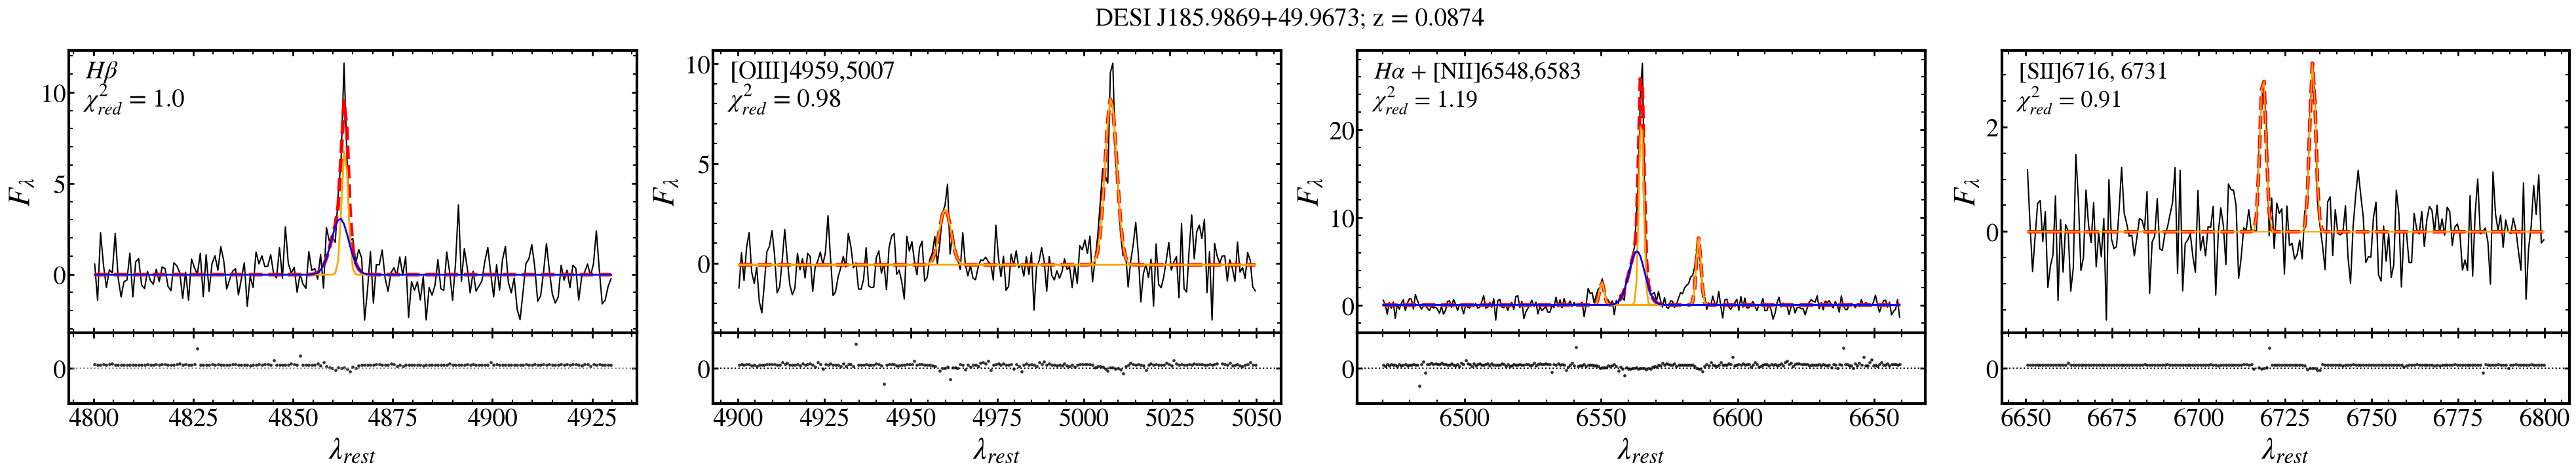

In [20]:
tgt = 39633248128599724
ii = np.nonzero(t['TARGETID'].data == tgt)[0][0]
f, _ = wrapper_example_fit(ii)
f

In [21]:
## 39633304432936658 --> Double peak + outflow component
## 39628317069936962 --> Outflow+Broad, with redshifted outflow component.
## 39627823803011222 --> Outflow + broad component --> more preferred
## 39627806656698042 --> Outflow + broad component

### 1. Missed Outflow in [OIII]

INFO:spectra.py:469:read_spectra: iotime 0.919 sec to read spectra from:  coadd-main-dark-22569.fits at 2026-10-05T10:53:21.332403
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.058 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.141 sec to read spectra from:  coadd-main-dark-22569.fits at 2026-10-05T10:53:24.021717
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


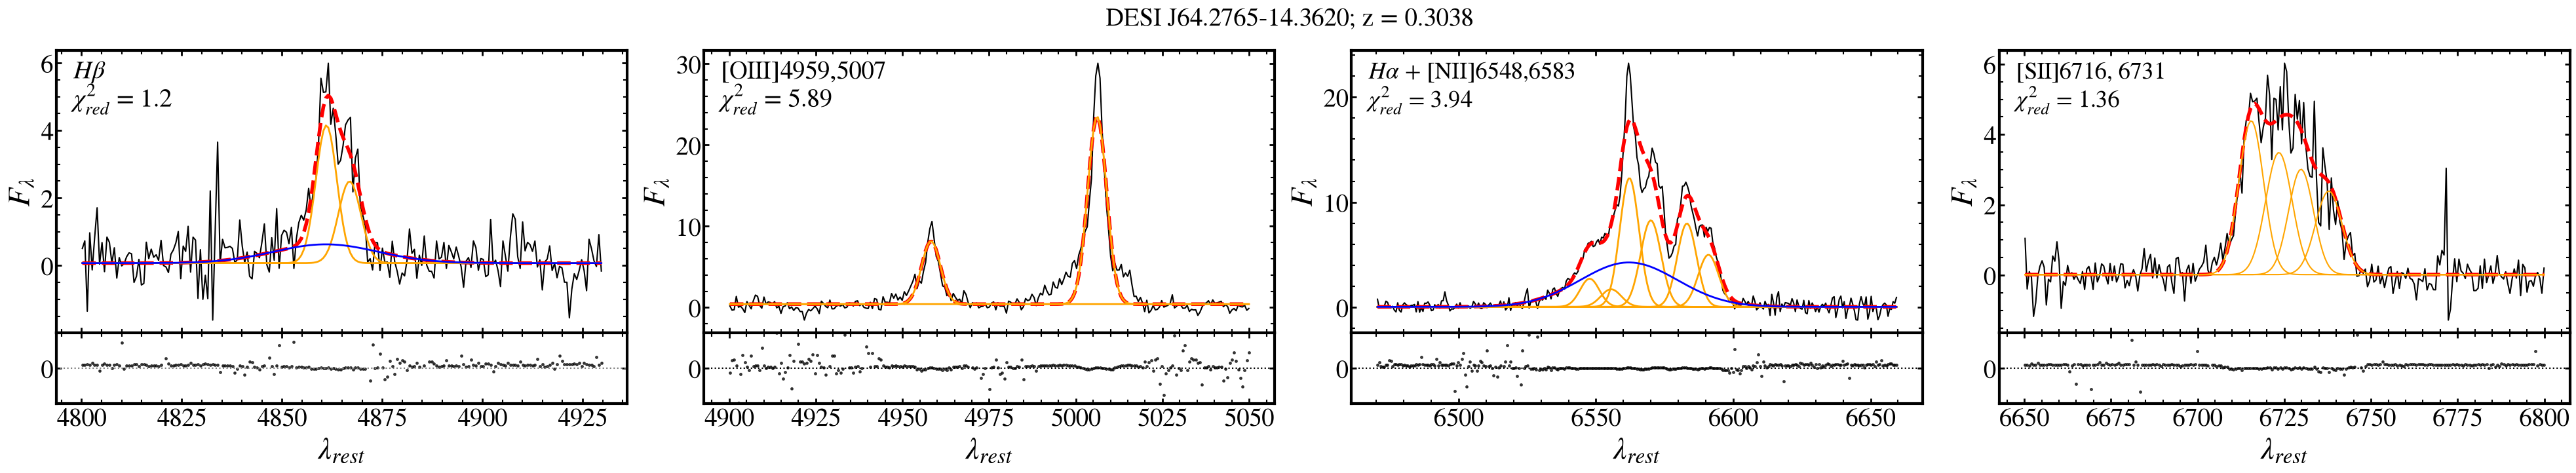

In [22]:
tgt = 39627444835061057
ii = np.nonzero(t['TARGETID'].data == tgt)[0][0]
f_oiii_missed, h_oiii_missed = wrapper_example_fit(ii)
f_oiii_missed

In [23]:
# f_oiii_missed.savefig('11_Missed_Outflow.png')
# h_oiii_missed.writeto('../catalogs/paper_figures/Fig12a_MissedOutflow.fits', overwrite = True)

### 1a. Missed Second Component

INFO:spectra.py:469:read_spectra: iotime 1.782 sec to read spectra from:  coadd-special-other-27333.fits at 2026-10-05T10:53:28.556249
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.362 sec to read spectra from:  coadd-special-other-27333.fits at 2026-10-05T10:53:32.106878
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]


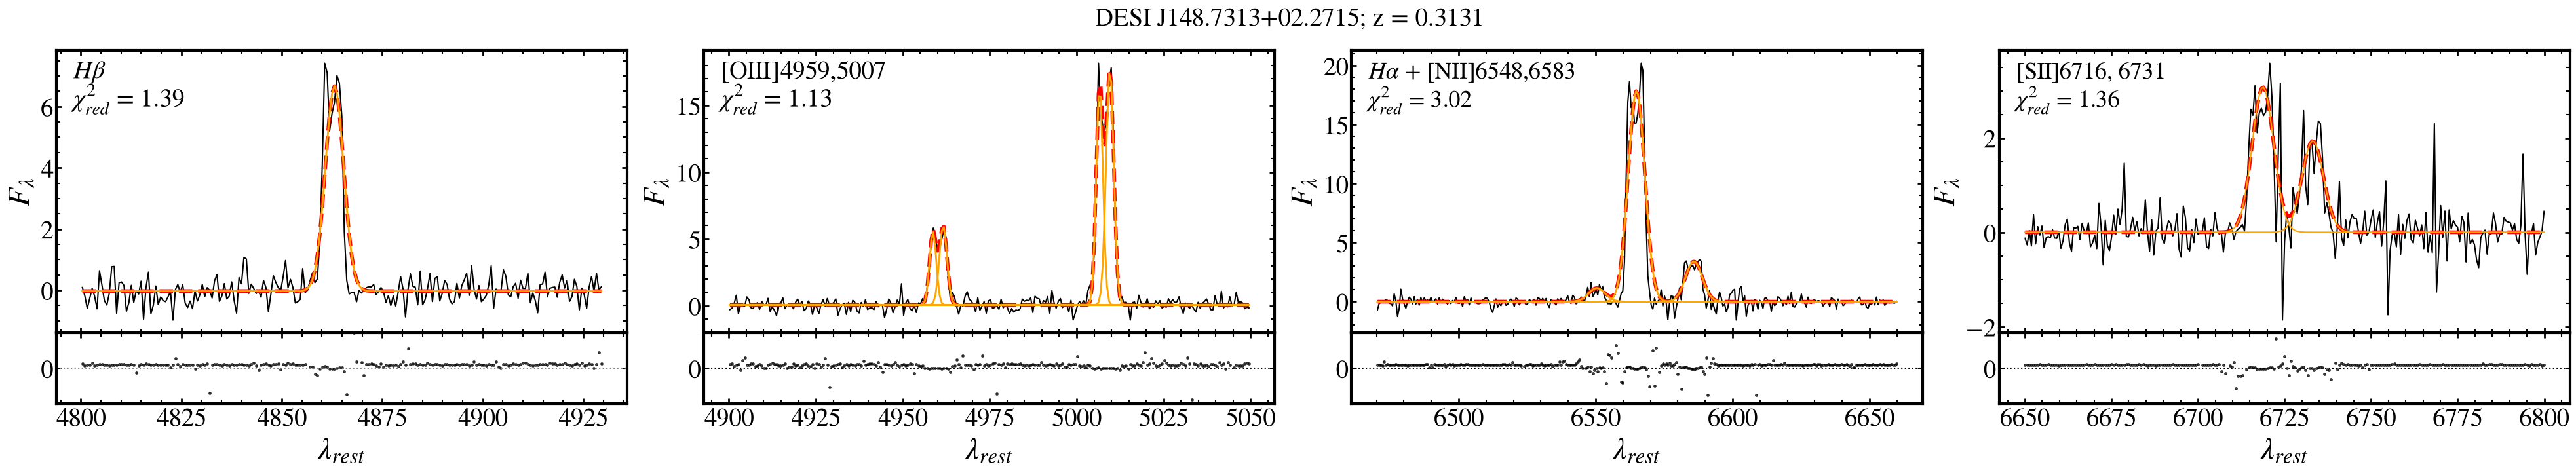

In [24]:
tgt = 39089837394965960
ii = np.nonzero(t['TARGETID'].data == tgt)[0][0]
f_dbl_missed, h_dbl_missed = wrapper_example_fit(ii)
f_dbl_missed

In [25]:
# f_dbl_missed.savefig('12_Missed_doublepeak.png')
# h_dbl_missed.writeto('../catalogs/paper_figures/Fig12b_Missed_doublepeak.fits', overwrite = True)

### 2. Forced Extra component

In [26]:
np.nonzero(is_nl&(is_oiii_out&is_oiii_dbl)&himass)[0][100:120]

array([39480, 39643, 39672, 39771, 39856, 39921, 40198, 41925, 42672,
       42810, 43892, 45216, 45276, 45483, 45741, 46258, 46701, 46720,
       48196, 48378])

INFO:spectra.py:469:read_spectra: iotime 3.083 sec to read spectra from:  coadd-main-dark-9732.fits at 2026-10-05T10:53:38.525520
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.525 sec to read spectra from:  coadd-main-dark-9732.fits at 2026-10-05T10:53:43.108050
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


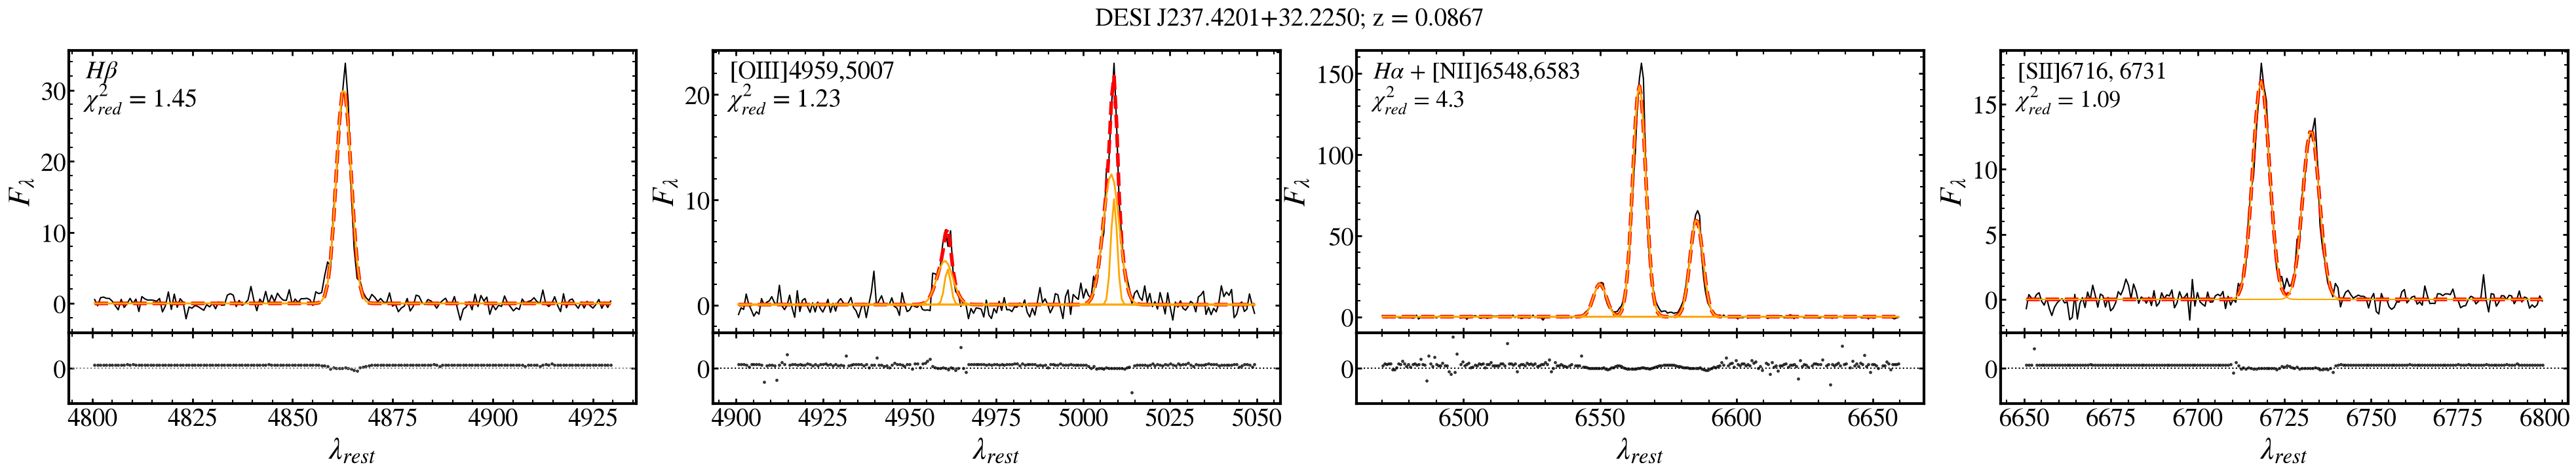

In [27]:
ii = 40198
f_forced, h_forced = wrapper_example_fit(ii)
f_forced

In [28]:
# f_forced.savefig('13_Forced_Extra.png')
# h_forced.writeto('../catalogs/paper_figures/Fig12c_ForcedExtra.fits', overwrite = True)

### 3. Missed Outflow Candidate

INFO:spectra.py:469:read_spectra: iotime 0.209 sec to read spectra from:  coadd-main-bright-10993.fits at 2026-10-05T10:53:47.448045
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.206 sec to read spectra from:  coadd-main-bright-10993.fits at 2026-10-05T10:53:50.265789
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.061 [sec]


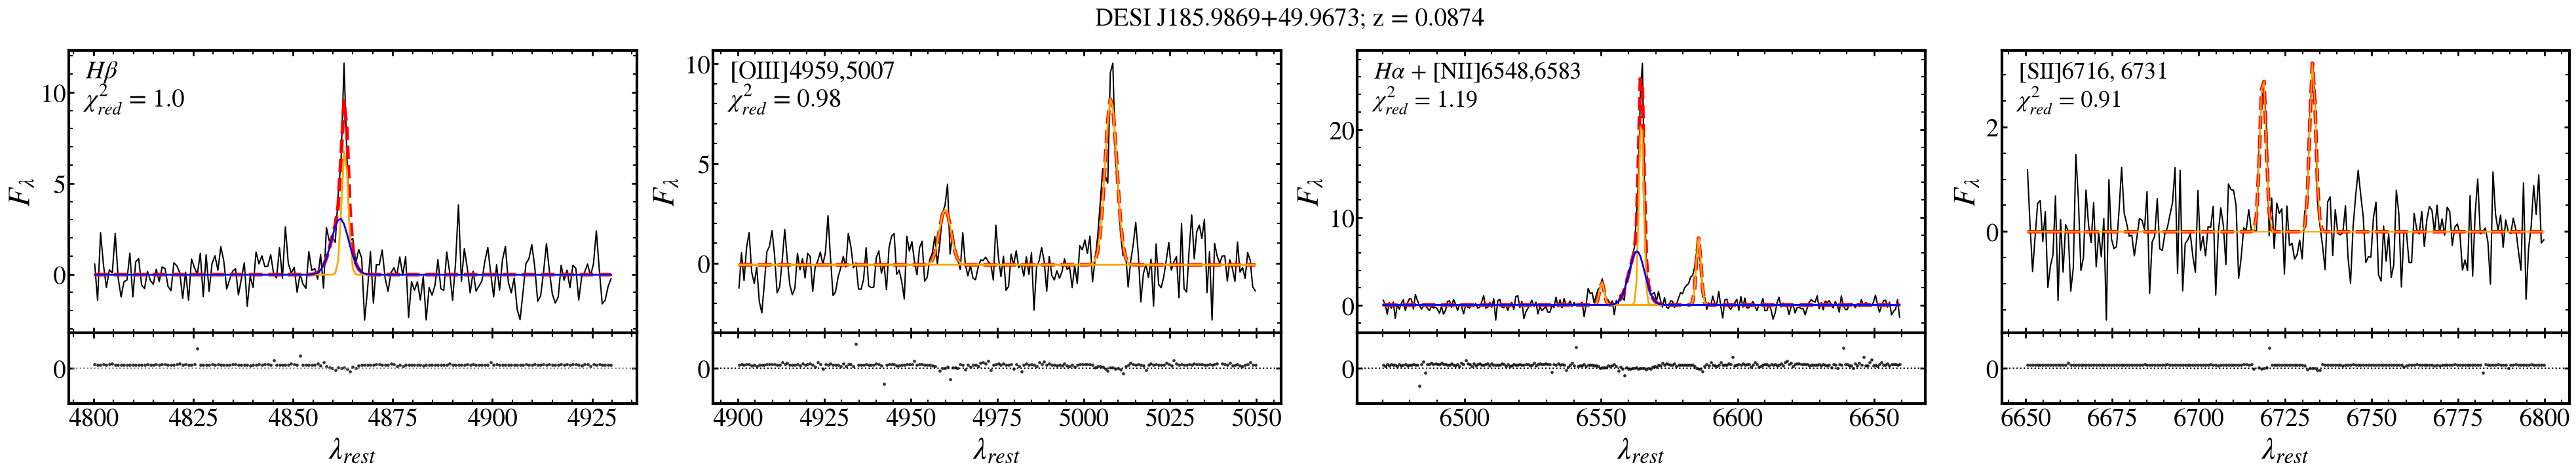

In [29]:
tgt = 39633248128599724
ii = np.nonzero(t['TARGETID'].data == tgt)[0][0]
f_missed, h_missed = wrapper_example_fit(ii)
f_missed

In [30]:
# f_missed.savefig('14_Missed_Outflow_Broad.png')
# h_missed.writeto('../catalogs/paper_figures/Fig14a_MissedOutflow_Broad.fits', overwrite = True)

### 4. Tentative Broad-Line Component

INFO:spectra.py:469:read_spectra: iotime 3.243 sec to read spectra from:  coadd-main-dark-0.fits at 2026-10-05T10:53:56.369470
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.355 sec to read spectra from:  coadd-main-dark-0.fits at 2026-10-05T10:54:00.116096
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]


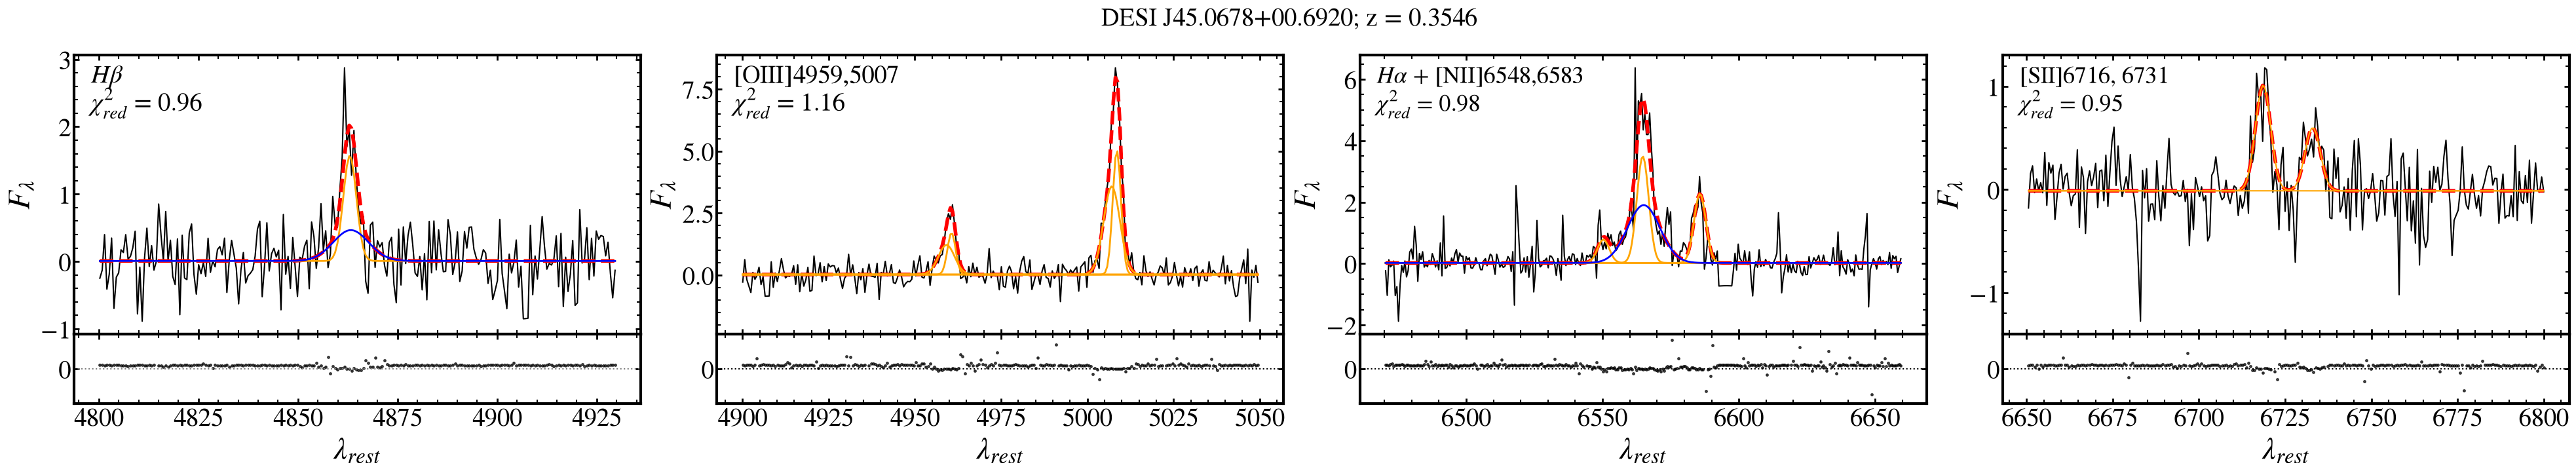

In [31]:
tgt = 39627803603241051 
ii = np.nonzero(t['TARGETID'].data == tgt)[0][0]
f_tent, h_tent = wrapper_example_fit(ii)
f_tent

In [32]:
# f_tent.savefig('15_Tentative_BL.png')
# h_tent.writeto('../catalogs/paper_figures/Fig14b_Tentative_BL.fits', overwrite = True)

### 5. Complicated Kinematics - BL Candidate

INFO:spectra.py:469:read_spectra: iotime 2.683 sec to read spectra from:  coadd-main-bright-26812.fits at 2026-10-05T10:54:06.267219
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.297 sec to read spectra from:  coadd-main-bright-26812.fits at 2026-10-05T10:54:09.811184
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


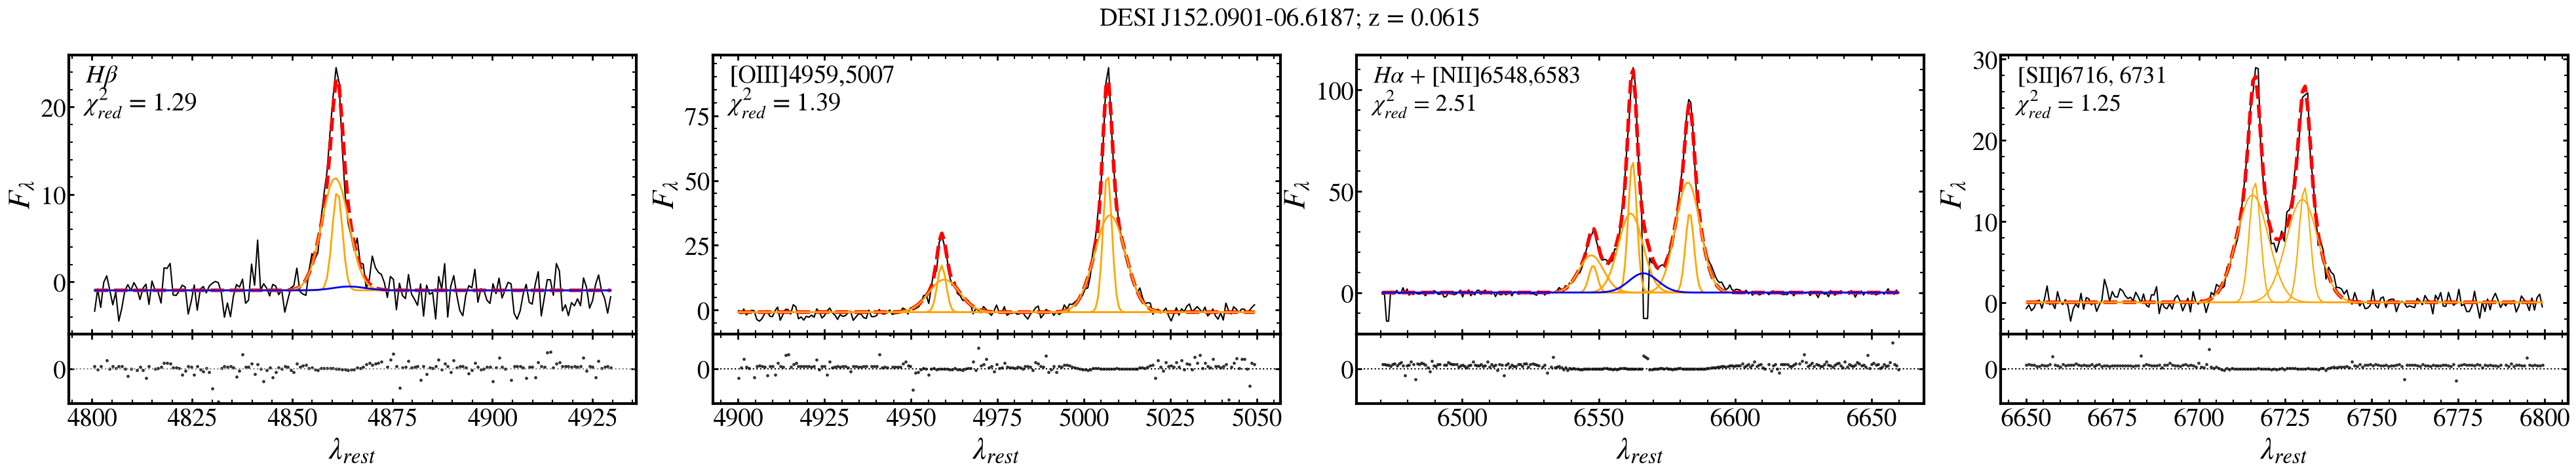

In [33]:
tgt = 39627630479152697
ii = np.nonzero(t['TARGETID'].data == tgt)[0][0]
f_comp, h_comp = wrapper_example_fit(ii)
f_comp

In [34]:
# f_comp.savefig('16_complicated_BL.png')
# h_comp.writeto('../catalogs/paper_figures/Fig14c_Complicated_BL.fits', overwrite = True)

### 6. Good Fit - but, complicated kinematics

INFO:spectra.py:469:read_spectra: iotime 2.477 sec to read spectra from:  coadd-main-bright-25821.fits at 2026-10-05T10:54:15.252024
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.272 sec to read spectra from:  coadd-main-bright-25821.fits at 2026-10-05T10:54:18.444913
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]


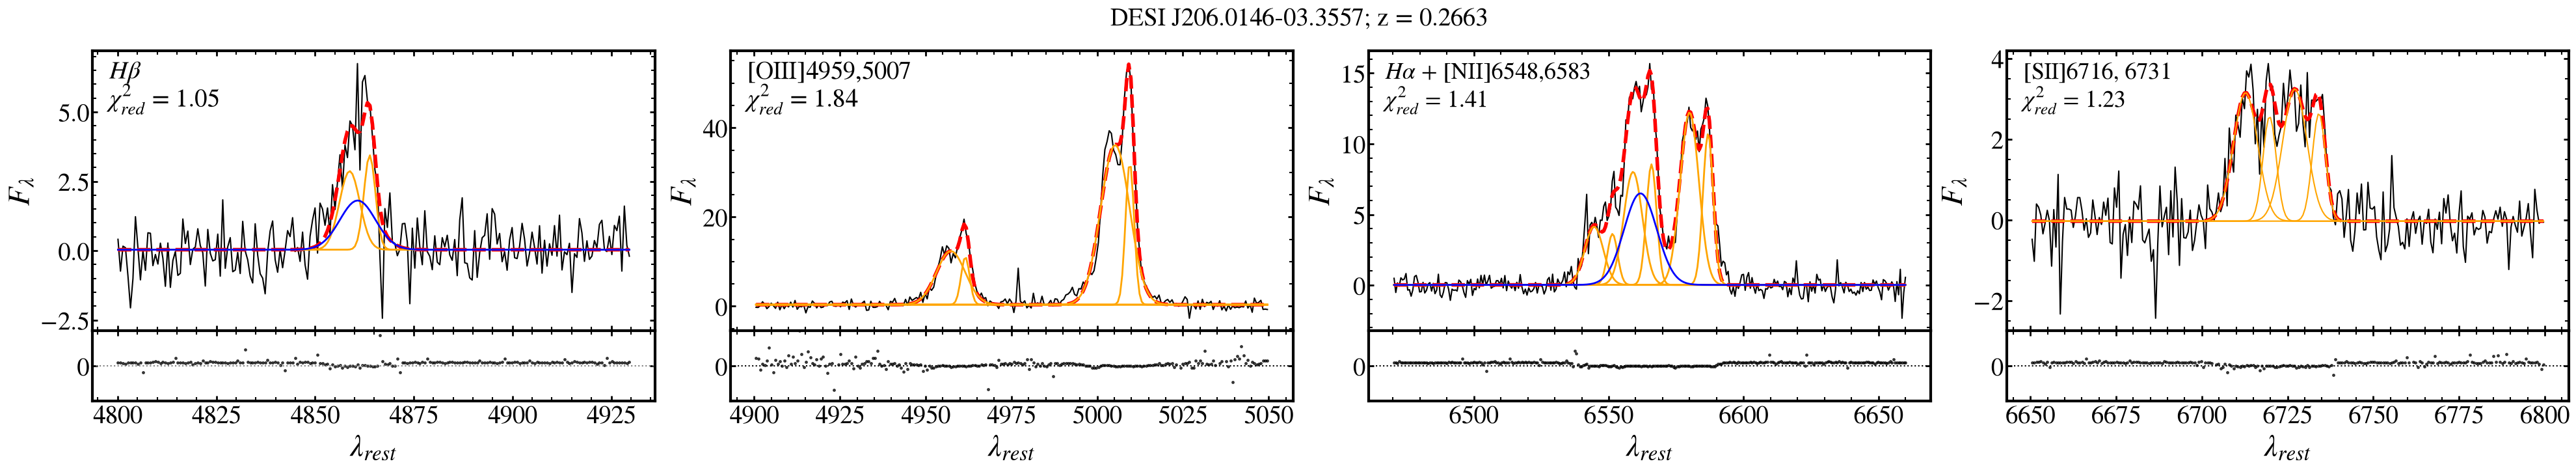

In [35]:
tgt = 39627709667611890  
ii = np.nonzero(t['TARGETID'].data == tgt)[0][0]
f_good, h_good = wrapper_example_fit(ii)
f_good

In [36]:
# f_good.savefig('17_complicated_good_fit.png')
# h_good.writeto('../catalogs/paper_figures/Fig15a_complicated_good.fits', overwrite = True)

### 7. Bad Continuum Subtraction

In [37]:
np.nonzero((t['OIII_RCHI2'].data > 20)&is_bl)

(array([  81559,  368868,  485622,  805269, 3128316, 4082002, 4314187,
        4432973, 5503698]),)

INFO:spectra.py:469:read_spectra: iotime 0.640 sec to read spectra from:  coadd-sv1-dark-5072.fits at 2026-10-05T10:54:22.214878
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.072 sec to read spectra from:  coadd-sv1-dark-5072.fits at 2026-10-05T10:54:24.547031
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


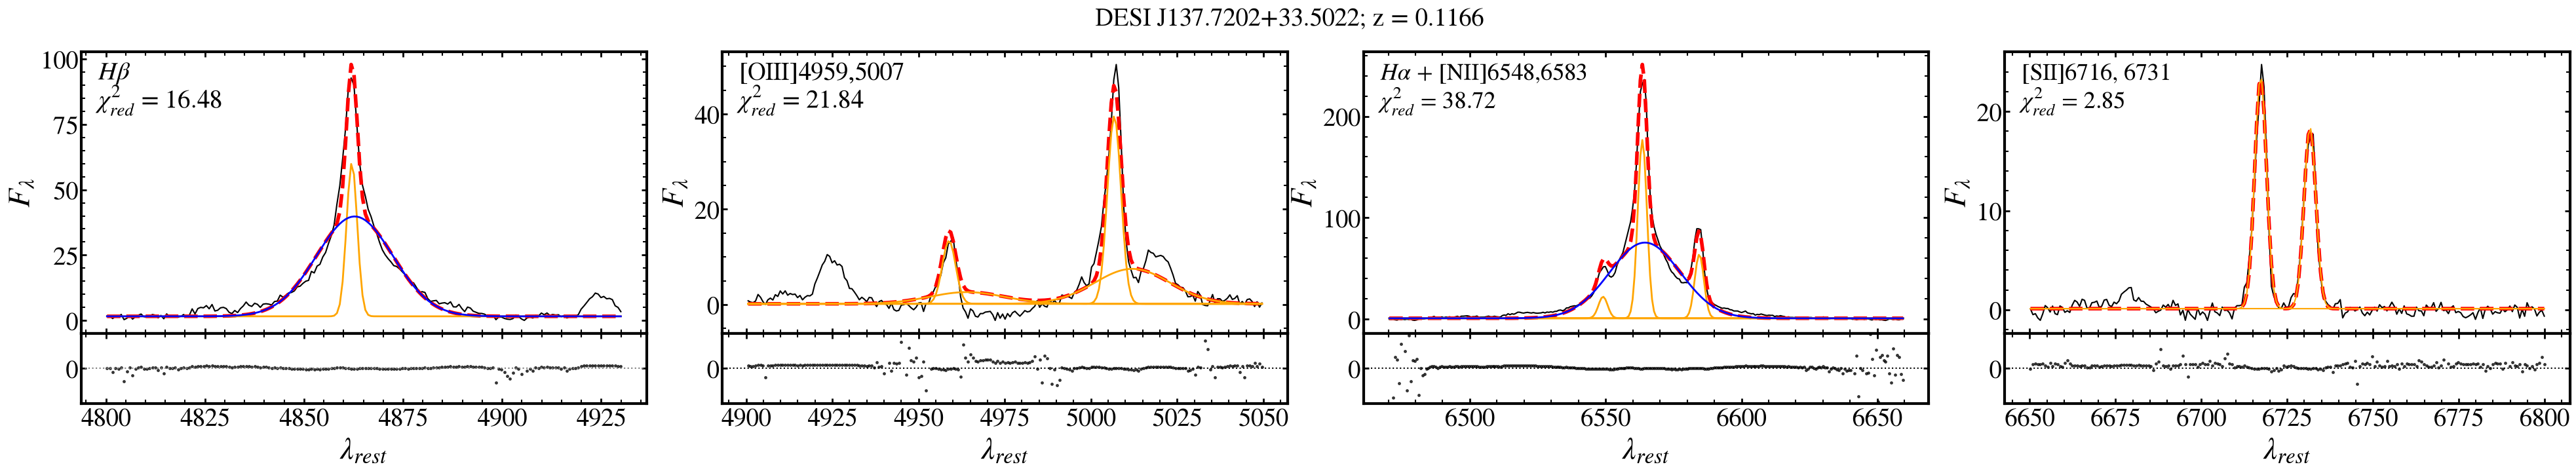

In [38]:
ii = 4314187 
f_bad, h_bad = wrapper_example_fit(ii)
f_bad

In [39]:
# f_bad.savefig('18_BadContinuum.png')
# h_bad.writeto('../catalogs/paper_figures/Fig15b_bad_continuum.fits', overwrite = True)

### 8a. Gaussian Approximation - Default Mode

INFO:spectra.py:469:read_spectra: iotime 1.868 sec to read spectra from:  coadd-main-dark-18793.fits at 2026-10-05T10:54:28.895823
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.194 sec to read spectra from:  coadd-main-dark-18793.fits at 2026-10-05T10:54:32.160573
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.059 [sec]


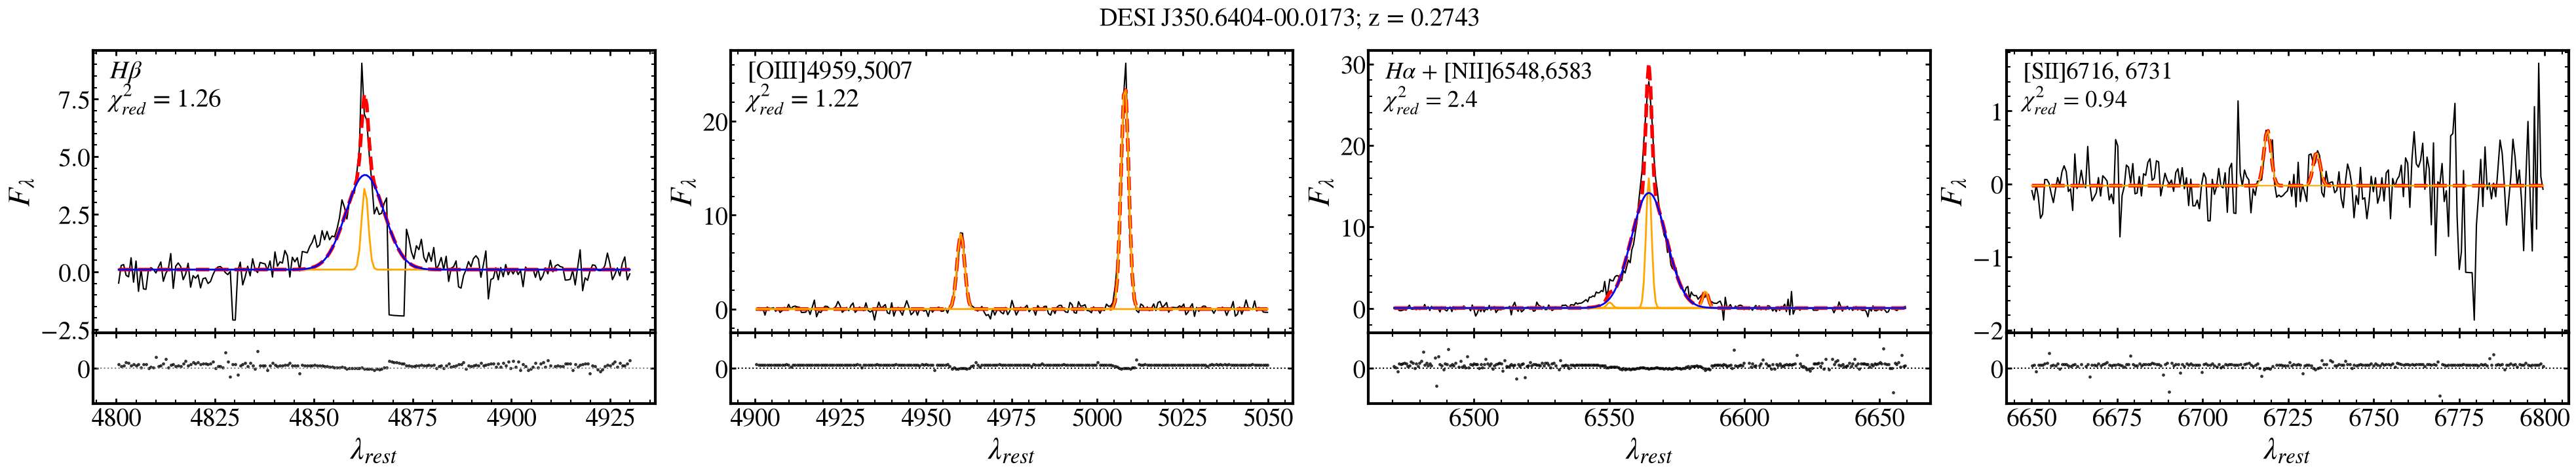

In [40]:
tgt = 39627790609290083  
ii = np.nonzero(t['TARGETID'].data == tgt)[0][0]
f_gauss_def, h_gauss_def = wrapper_example_fit(ii)
f_gauss_def

In [41]:
# f_gauss_def.savefig('19_Default_Gaussian.png')
# h_gauss_def.writeto('../catalogs/paper_figures/Fig13a_default_gaussian.fits', overwrite = True)

### 8b. Gaussian Approximation - EBL Mode

In [42]:
np.nonzero(is_ebl&(is_agn|is_comp)&(ha_b_fwhm > 2000)&is_bl&(t['NII_HA_SII_RCHI2'].data >= 20))[0]

array([  22782,   30833,   34815,   39537,  593933,  787804,  799875,
       2104236, 2258889, 2285529, 2456379, 2665903, 2685265, 2944686,
       2954176, 3201384, 3579893, 3879833, 3964372, 4588012, 5460469,
       5911843])

INFO:spectra.py:469:read_spectra: iotime 1.726 sec to read spectra from:  coadd-main-dark-4477.fits at 2026-10-05T10:54:36.836042
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.060 [sec]
INFO:spectra.py:469:read_spectra: iotime 0.208 sec to read spectra from:  coadd-main-dark-4477.fits at 2026-10-05T10:54:39.826025
INFO:coaddition.py:1395:coadd_cameras: coadding spectra across cameras took: 0.061 [sec]


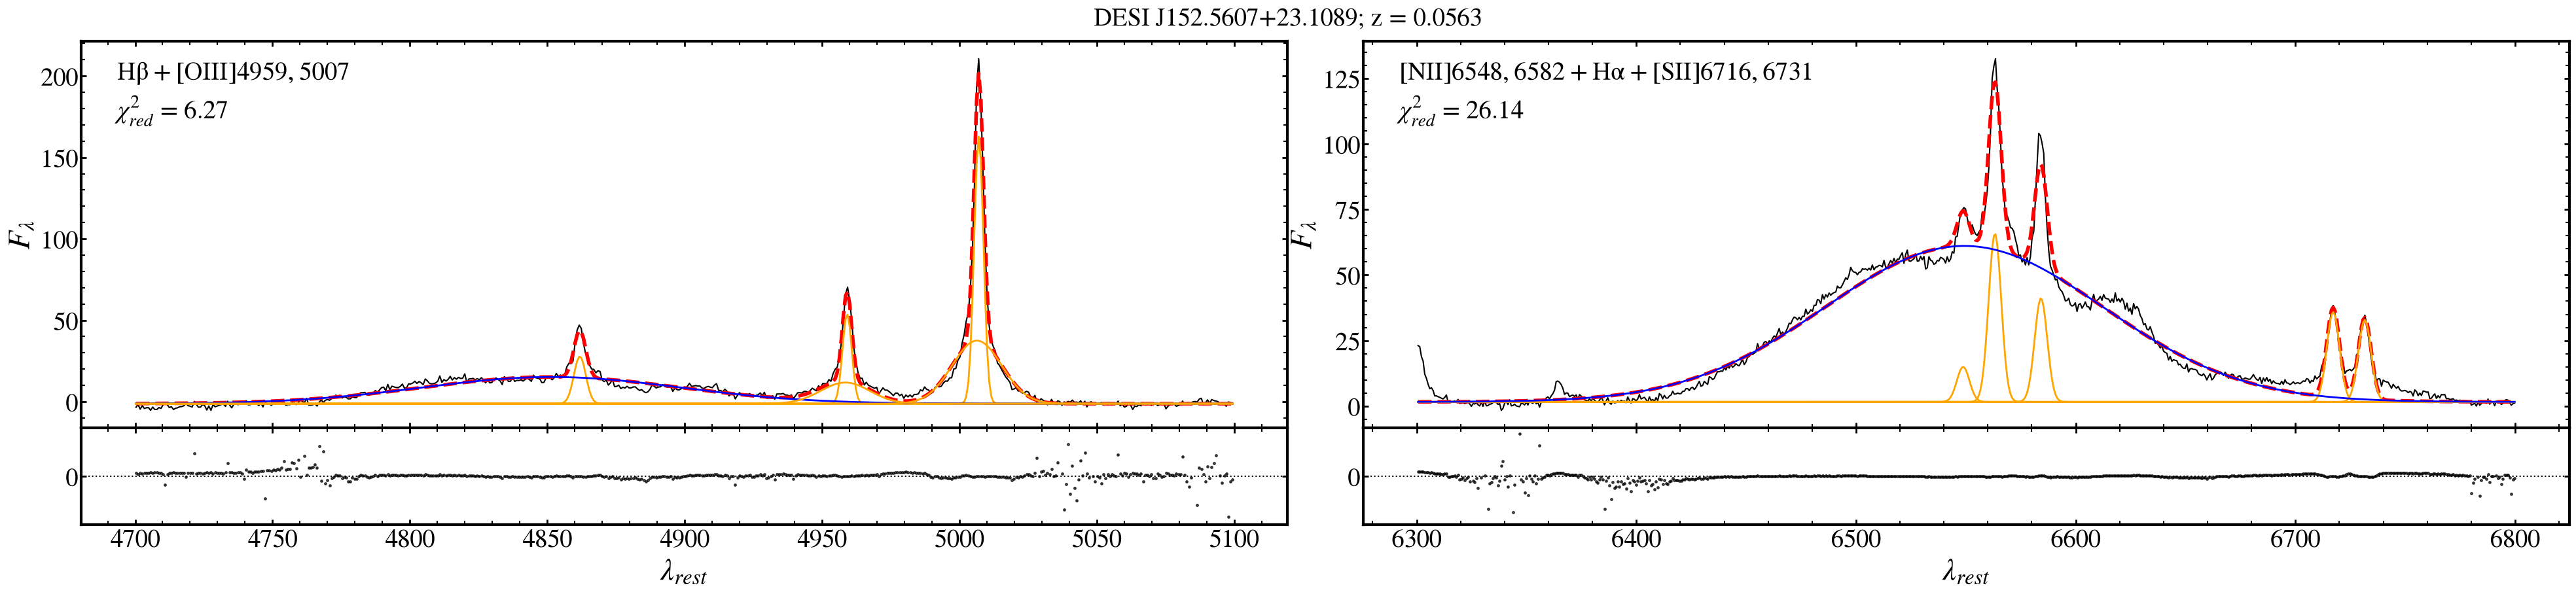

In [43]:
ii = 3579893
f_gauss_ebl, h_gauss_ebl = wrapper_example_fit(ii, ver='ebl')
f_gauss_ebl

In [44]:
# f_gauss_ebl.savefig('19b_EBL_Gaussian.png')
# h_gauss_ebl.writeto('../catalogs/paper_figures/Fig13b_ebl_gaussian.fits', overwrite = True)

---